# Label preprocessing: unified 6-class manifest

Unifies **RealWaste, TrashNet, SortWaste and TACO** under one schema
(`cardboard, glass, metal, paper, plastic, trash`). All logic lives in `src/data_preprocessing/`;
this notebook only calls it and shows the results.

- Label rules: `configs/label_mapping.json` (single source of truth)
- TACO folds: `configs/taco_folds.csv` (fixed; do not regenerate after results exist)
- Rebuild files from the repo root: `python scripts/build_manifest.py`
- Tests: `python -m unittest tests.test_data_preprocessing`

In [1]:
import sys
from pathlib import Path

import pandas as pd


def find_repo_root(start: Path) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "data" / "raw").is_dir() and (candidate / ".git").exists():
            return candidate
    raise FileNotFoundError("Could not find repository root containing data/raw and .git")


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT / "src"))

from data_preprocessing import (DataPaths, build_manifest, class_table, exclusion_table, inventory,
                                load_config, validate_manifest)
from data_preprocessing.report import (plot_annotated_frames, plot_box_sizes, plot_class_distribution,
                                       plot_sample_grid, plot_taco_trash)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

paths = DataPaths(REPO_ROOT)
assert not paths.missing(), paths.missing()
config = load_config(paths.config)
REPO_ROOT

PosixPath('/Users/hanjoo/Documents/UC Berkeley/Coursework/COMPSCI289A/grad_project/TrashClassifierYoloCNN')

## 1. Build and validate the manifest

One row per classification example: a whole image (RealWaste/TrashNet) or one bounding box (SortWaste/TACO). Excluded examples stay in the manifest with `exclude_reason`, so mappings can change without re-reading raw data.

In [2]:
manifest = build_manifest(paths, config)
validate_manifest(manifest, config)   # raises with a list of every failed check
print(f"{len(manifest):,} rows, all checks passed")
manifest.groupby(["dataset", "example_type"]).size().rename("rows").to_frame()

99,592 rows, all checks passed


rows
dataset   example_type       
realwaste whole_image    4752
sortwaste bounding_box  87525
          no_object         4
taco      bounding_box   4784
trashnet  whole_image    2527

## 2. Dataset inventory

In [3]:
inventory(manifest, config)

,task,images,boxes,original_classes,common_classes_covered,classifier_examples,structure
dataset,,,,,,,
realwaste,classification,4752,<NA>,9,6,3587,class folders; 80/10/10 split generated (seed 42)
trashnet,classification,2527,<NA>,6,6,2521,class folders; 80/10/10 split generated (seed 42)
sortwaste,detection,5261,87525,8,3,68298,official train/val/test
taco,detection,1500,4784,59,6,3627,15 batches -> 3 batch folds (external test)


### What the data looks like

One example per dataset and class (empty cells = the dataset has no such class), then one detection frame per box dataset. Dashed grey boxes are kept for the detector only.

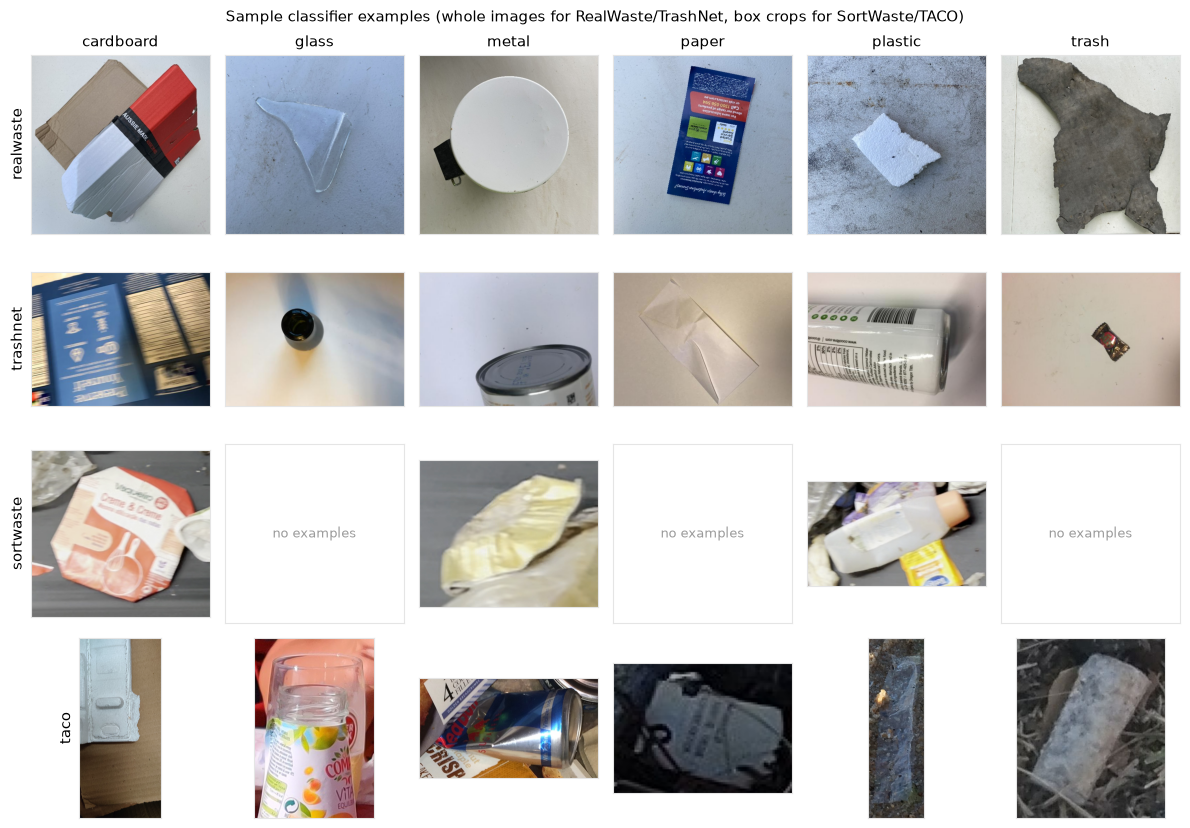

In [4]:
fig = plot_sample_grid(manifest, paths, config['common_labels'])

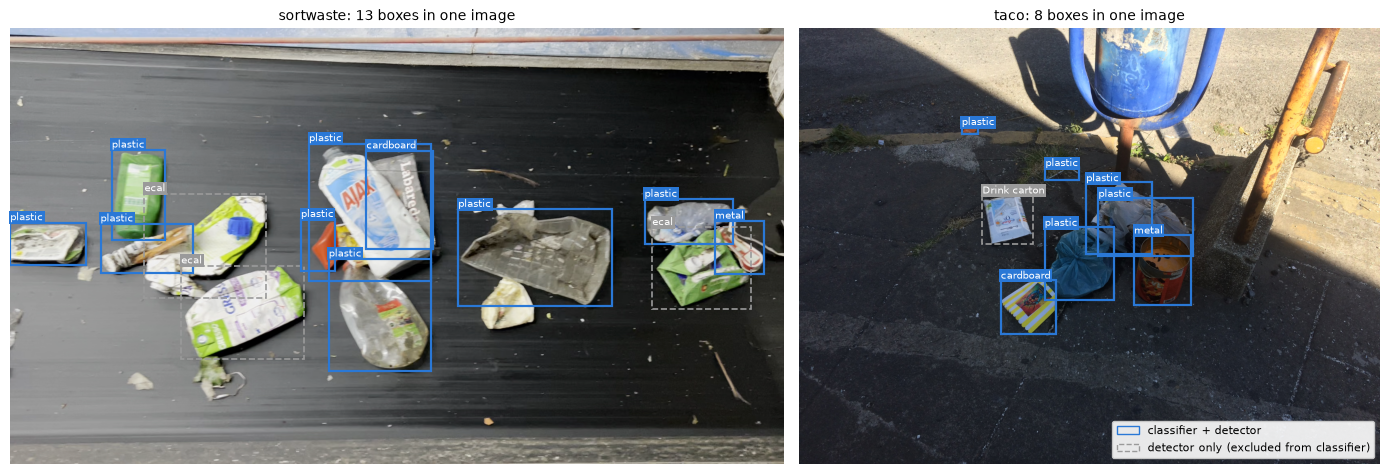

In [5]:
fig = plot_annotated_frames(manifest, paths)

## 3. Label mapping

Detector uses every box as one `waste_object` class. The classifier only uses labels whose material is unambiguous, and only crops with a short side of at least 32 px.

In [6]:
labelled = manifest[manifest["example_type"] != "no_object"]
mapping = (
    labelled.groupby(["dataset", "original_label", "common_label"])
    .agg(rows=("dataset", "size"), classifier_rows=("use_classifier_eval", "sum"),
         detector=("use_detector_train", "any"))
    .reset_index()
)
label_reason = (manifest.dropna(subset=["exclude_reason"])
                .query("~exclude_reason.str.startswith('crop short side')", engine="python")
                .groupby(["dataset", "original_label"])["exclude_reason"].first())
mapping = mapping.join(label_reason, on=["dataset", "original_label"]).fillna({"exclude_reason": ""})
for ds in ["realwaste", "trashnet", "sortwaste"]:
    display(mapping[mapping["dataset"] == ds].drop(columns="dataset").set_index("original_label"))

,common_label,rows,classifier_rows,detector,exclude_reason
original_label,,,,,
Cardboard,cardboard,461,461,False,
Food Organics,trash,411,0,False,organic; not a material class
Glass,glass,420,420,False,
Metal,metal,790,790,False,
Miscellaneous Trash,trash,495,495,False,
Paper,paper,500,500,False,
Plastic,plastic,921,921,False,
Textile Trash,trash,318,0,False,textile; not a material class
Vegetation,trash,436,0,False,organic; not a material class


,common_label,rows,classifier_rows,detector,exclude_reason
original_label,,,,,
cardboard,cardboard,403,403,False,
glass,glass,501,498,False,identical image filed under different classes
metal,metal,410,409,False,identical image filed under different classes
paper,paper,594,594,False,
plastic,plastic,482,480,False,identical image filed under different classes
trash,trash,137,137,False,


,common_label,rows,classifier_rows,detector,exclude_reason
original_label,,,,,
cardboard,cardboard,2156,2156,True,
ecal,cardboard,19227,0,True,composite beverage carton; material ambiguous
metal,metal,1437,1437,True,
mixed_plastic_rigid,plastic,9416,9416,True,
mixed_plastic_soft,plastic,12337,12337,True,
pead,plastic,25044,25044,True,
pet,plastic,16806,16806,True,
pet_oleo,plastic,1102,1102,True,


In [7]:
# TACO: 59 categories with annotations, grouped by common label
taco_map = mapping[mapping["dataset"] == "taco"].sort_values(["common_label", "rows"], ascending=[True, False])
taco_map.drop(columns="dataset").set_index(["common_label", "original_label"])

rows  classifier_rows  detector                                             exclude_reason
common_label original_label                                                                                                       
cardboard    Other carton                 93               93      True                                                           
             Corrugated carton            64               64      True                                                           
             Drink carton                 45                0      True  composite beverage carton; consistent with SortWaste ECAL
             Meal carton                  30               30      True                                                           
             Egg carton                   11               11      True                                                           
             Toilet tube                   5                4      True                                                           
             Pizza box                     3                3      True                                                           
glass        Broken glass                138               88      True                                                           
             Glass bottle                104              104      True                                                           
             Glass cup                     6                6      True                                                           
             Glass jar                     6                6      True                                                           
metal        Drink can                   229              224      True                                                           
             Pop tab                      99               72      True                                                           
             Metal bottle cap             80               66      True                                                           
             Aluminium foil               62               62      True                                                           
             Food Can                     34               34      True                                                           
             Scrap metal                  20               19      True                                                           
             Aerosol                      10               10      True                                                           
             Metal lid                    10               10      True                                                           
paper        Normal paper                 82               80      True                                                           
             Paper cup                    67               67      True                                                           
             Paper bag                    27               27      True                                                           
             Magazine paper               12               12      True                                                           
             Wrapping paper               12               12      True                                                           
             Paper straw                   4                4      True                                                           
plastic      Plastic film                451              447      True                                                           
             Clear plastic bottle        285              284      True                                                           
             Other plastic               273              238      True                                                           
             Other plastic wrapper       260              258      True                                       

## 4. Class distribution (classifier-eligible examples)

common_label,cardboard,glass,metal,paper,plastic,trash
dataset,,,,,,
realwaste,461,420,790,500,921,495
trashnet,403,498,409,594,480,137
sortwaste,2156,0,1437,0,64705,0
taco,205,204,497,202,2095,424


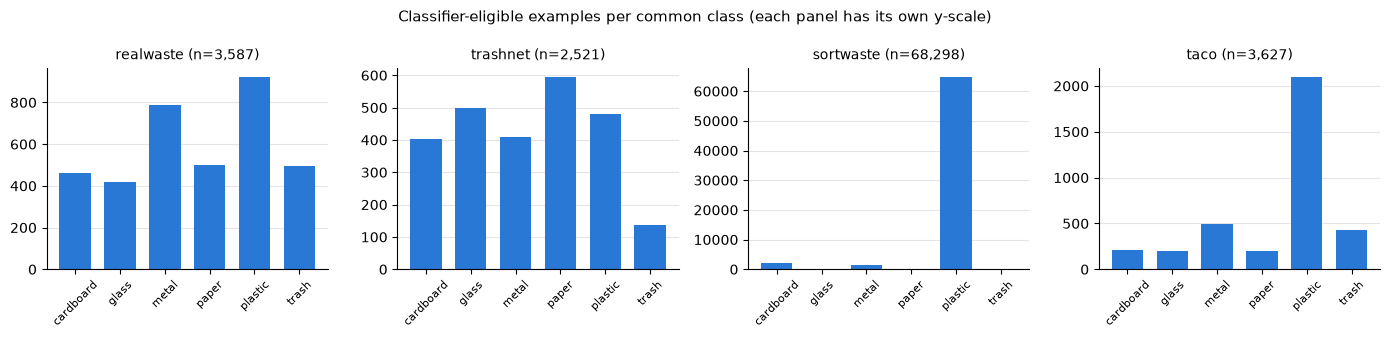

In [8]:
table = class_table(manifest, config)
display(table)
fig = plot_class_distribution(table, "Classifier-eligible examples per common class (each panel has its own y-scale)")

In [9]:
# Detector side: SortWaste boxes per common label before classifier exclusions
detector_table = class_table(manifest, config, column="use_detector_eval")
detector_table

common_label,cardboard,glass,metal,paper,plastic,trash
dataset,,,,,,
realwaste,0,0,0,0,0,0
trashnet,0,0,0,0,0,0
sortwaste,21383,0,1437,0,64705,0
taco,251,254,544,204,2206,1325


## 5. Exclusions

In [10]:
exclusion_table(manifest)

,dataset,exclude_reason,original_label,rows
1,realwaste,organic; not a material class,Vegetation,436
0,realwaste,organic; not a material class,Food Organics,411
2,realwaste,textile; not a material class,Textile Trash,318
3,sortwaste,composite beverage carton; material ambiguous,ecal,19227
4,sortwaste,no objects in image,NaN,4
25,taco,material unknown,Unlabeled litter,517
7,taco,crop short side < 32px,Cigarette,340
6,taco,crop short side < 32px,Broken glass,50
5,taco,composite beverage carton; consistent with SortWaste ECAL,Drink carton,45
15,taco,crop short side < 32px,Plastic bottle cap,37


## 6. Known data issues

In [11]:
sw = manifest[manifest["dataset"] == "sortwaste"]
sw_boxes = sw[sw["example_type"] == "bounding_box"]
taco = manifest[manifest["dataset"] == "taco"]
taco_trash = taco[(taco["common_label"] == "trash") & taco["use_classifier_eval"]]
cig = (taco_trash["original_label"] == "Cigarette").sum()

findings = {
    "SortWaste boxes (docs say 87,252)": len(sw_boxes),
    "SortWaste images with an empty label file": (sw["example_type"] == "no_object").sum(),
    "SortWaste share plastic / cardboard / metal (all boxes)":
        " / ".join(f"{sw_boxes['common_label'].eq(c).mean():.1%}" for c in ["plastic", "cardboard", "metal"]),
    "SortWaste cardboard boxes that are ECAL cartons": f"{sw_boxes['original_label'].eq('ecal').sum() / sw_boxes['common_label'].eq('cardboard').sum():.1%}",
    "TrashNet files that are byte-identical across two classes": manifest["exclude_reason"].eq("identical image filed under different classes").sum(),
    "TACO trash eval crops / of which cigarettes": f"{len(taco_trash)} / {cig} ({cig / len(taco_trash):.0%})",
    "TACO trash eval crops without cigarettes": len(taco_trash) - cig,
    "TACO boxes below 32 px (detector only)": taco["exclude_reason"].fillna("").str.startswith("crop short side").sum(),
    "TACO glass: boxes / images": f"{taco['common_label'].eq('glass').sum()} / {taco.loc[taco['common_label'].eq('glass'), 'source_image_id'].nunique()}",
}
pd.Series(findings, name="value").to_frame()

,value
"SortWaste boxes (docs say 87,252)",87525
SortWaste images with an empty label file,4
SortWaste share plastic / cardboard / metal (all boxes),73.9% / 24.4% / 1.6%
SortWaste cardboard boxes that are ECAL cartons,89.9%
TrashNet files that are byte-identical across two classes,6
TACO trash eval crops / of which cigarettes,424 / 327 (77%)
TACO trash eval crops without cigarettes,97
TACO boxes below 32 px (detector only),551
TACO glass: boxes / images,254 / 95


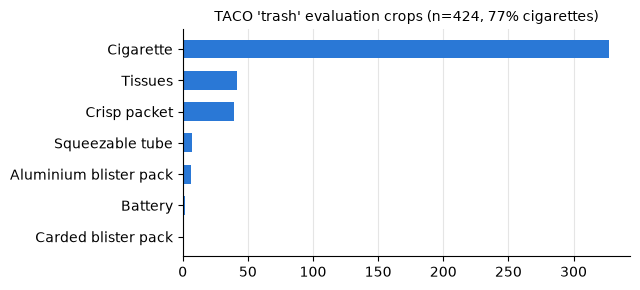

In [12]:
fig = plot_taco_trash(manifest)

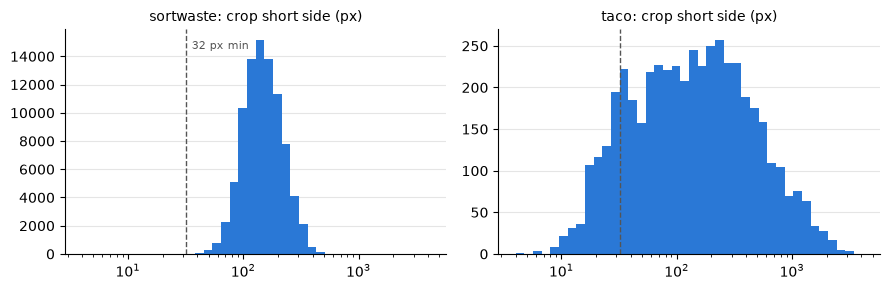

In [13]:
fig = plot_box_sizes(manifest)

## 7. Splits and TACO folds

- **RealWaste / TrashNet**: stratified 80/10/10 per original class, seed 42; byte-identical images share a split.
- **SortWaste**: official train/val/test, all boxes of an image stay in its split.
- **TACO**: no fixed split. 15 batches are grouped into 3 equal folds chosen by exhaustive search to balance images, boxes and every class; saved once to `configs/taco_folds.csv`.

In [14]:
partition = manifest["split"].fillna("fold" + manifest["taco_fold"].astype("string"))
eligible = manifest[manifest["use_classifier_eval"]]
pd.crosstab([eligible["dataset"], partition[eligible.index]], eligible["common_label"], margins=True)

common_label     cardboard  glass  metal  paper  plastic  trash    All
dataset   split                                                       
realwaste test          46     42     79     50       92     49    358
          train        369    336    632    400      737    396   2870
          val           46     42     79     50       92     50    359
sortwaste test         207      0    215      0     9170      0   9592
          train       1524      0    945      0    45724      0  48193
          val          425      0    277      0     9811      0  10513
taco      fold0         74     73    193     77      643    131   1191
          fold1         57     58    161     66      647    151   1140
          fold2         74     73    143     59      805    142   1296
trashnet  test          40     50     41     59       48     14    252
          train        322    399    327    475      385    110   2018
          val           41     49     41     60       47     13    251
All                   3225   1122   3133   1296    68201   1056  78033

In [15]:
folds = taco.groupby("taco_fold").agg(batches=("taco_batch", lambda b: sorted(b.unique())),
                                      images=("source_image_id", "nunique"), boxes=("dataset", "size"))
folds.join(pd.crosstab(taco_trash["taco_fold"], taco_trash["original_label"] == "Cigarette")
           .rename(columns={True: "trash_cigarette", False: "trash_other"}))

,batches,images,boxes,trash_other,trash_cigarette
taco_fold,,,,,
0,"[1, 3, 7, 9, 14]",525,1481,38,93
1,"[2, 5, 10, 13, 15]",489,1559,36,115
2,"[4, 6, 8, 11, 12]",486,1744,23,119


## 8. Fixed evaluation policy

1. **Detector** (`waste_object`, single class): D1 = SortWaste, D2 = SortWaste + TACO train folds.
   Evaluated on the SortWaste official test and on out-of-fold TACO batches (3-fold, grouped by batch).
2. **Classifier**: trained on ground-truth crops only (C1 TrashNet, C2 RealWaste, C3 both, C4 + SortWaste).
   Never trained on TACO; TACO ground-truth crops are the external test.
3. **Model selection** uses validation splits only (mean macro-F1 over the available validation sets);
   TACO results are looked at once, after every setting is frozen.
4. Classifier crops need a **short side >= 32 px** (same rule for every dataset).
5. **Trash** results are reported **with and without cigarettes**.
6. **Shared-3** (`cardboard, metal, plastic`) is the protocol for comparing against the SortWaste-only YOLO baseline;
   ECAL boxes and predictions matched to them are ignored in that scoring.
7. Unlabeled litter counts for detection recall but not for classification accuracy.